# Zuber — Análise de corridas de táxi em Chicago

**Contexto.** A Zuber é uma nova empresa de compartilhamento de caronas que está chegando a Chicago. Como analista, meu objetivo é entender as preferências dos passageiros e o impacto de fatores externos (como o clima) nas corridas.

**Estrutura do notebook**

1. Coleta de dados do clima (web scraping)
2. Consultas SQL (registro das consultas usadas para gerar os CSVs)
3. Análise exploratória de dados (Python)
   - Empresas de táxi × número de corridas
   - Top 10 bairros de destino
4. Teste de hipótese: o clima altera a duração das corridas Loop → O'Hare aos sábados?
5. Conclusão geral

## 0. Importação de bibliotecas e configurações

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from scipy import stats as st

# Configurações visuais padronizadas para todos os gráficos
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

## 1. Coleta de dados do clima em Chicago (novembro de 2017)

Os dados meteorológicos estão em uma tabela HTML. Uso `requests` para baixar a página e `BeautifulSoup` para localizar a tabela pelo atributo `id="weather_records"` e montar um DataFrame.

In [2]:
URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analyst-eng/moved_chicago_weather_2017.html'

req = requests.get(URL)
req.raise_for_status()  # interrompe a execução se a página não carregar
soup = BeautifulSoup(req.text, 'lxml')

table = soup.find('table', attrs={'id': 'weather_records'})

# Cabeçalhos da tabela
heading_table = [th.text for th in table.find_all('th')]

# Linhas de dados (ignorando a linha de cabeçalho)
content = []
for row in table.find_all('tr'):
    if not row.find_all('th'):
        content.append([td.text for td in row.find_all('td')])

weather_records = pd.DataFrame(content, columns=heading_table)
print(weather_records)

           Date and time Temperature       Description
0    2017-11-01 00:00:00     276.150     broken clouds
1    2017-11-01 01:00:00     275.700  scattered clouds
2    2017-11-01 02:00:00     275.610   overcast clouds
3    2017-11-01 03:00:00     275.350     broken clouds
4    2017-11-01 04:00:00     275.240     broken clouds
..                   ...         ...               ...
692  2017-11-29 20:00:00     281.340        few clouds
693  2017-11-29 21:00:00     281.690      sky is clear
694  2017-11-29 22:00:00     281.070        few clouds
695  2017-11-29 23:00:00     280.060      sky is clear
696  2017-11-30 00:00:00     278.460      sky is clear

[697 rows x 3 columns]


**Comentário:** a tabela foi extraída com sucesso e contém um registro por hora, com data/hora, temperatura e descrição do clima. Esses registros são a base usada no banco de dados para cruzar clima e corridas.

## 2. Consultas SQL (registro)

As consultas abaixo foram executadas no banco de dados da plataforma e geraram os arquivos CSV analisados nas próximas seções. Elas estão aqui como documentação do raciocínio.

**2.1 Corridas por empresa (15 a 16/11/2017)**
```sql
SELECT
    cabs.company_name,
    COUNT(trips.trip_id) AS trips_amount
FROM cabs
INNER JOIN trips ON trips.cab_id = cabs.cab_id
WHERE CAST(trips.start_ts AS date) BETWEEN '2017-11-15' AND '2017-11-16'
GROUP BY cabs.company_name
ORDER BY trips_amount DESC;
```

**2.2 Empresas com "Yellow" ou "Blue" (01 a 07/11/2017)**
```sql
SELECT
    cabs.company_name,
    COUNT(trips.trip_id) AS trips_amount
FROM cabs
INNER JOIN trips ON trips.cab_id = cabs.cab_id
WHERE CAST(trips.start_ts AS date) BETWEEN '2017-11-01' AND '2017-11-07'
  AND (cabs.company_name LIKE '%Yellow%' OR cabs.company_name LIKE '%Blue%')
GROUP BY cabs.company_name;
```

**2.3 Flash Cab, Taxi Affiliation Services e "Other" (novembro de 2017)**

O enunciado do projeto afirma que essas eram as empresas mais populares **em novembro de 2017**, então o filtro cobre o mês inteiro (01 a 30/11), e não apenas a primeira semana. Assim, a divisão entre as duas líderes e o grupo "Other" representa o mês todo.
```sql
SELECT
    CASE
        WHEN cabs.company_name IN ('Flash Cab', 'Taxi Affiliation Services') THEN cabs.company_name
        ELSE 'Other'
    END AS company,
    COUNT(trips.trip_id) AS trips_amount
FROM cabs
INNER JOIN trips ON trips.cab_id = cabs.cab_id
WHERE CAST(trips.start_ts AS date) BETWEEN '2017-11-01' AND '2017-11-30'
GROUP BY company
ORDER BY trips_amount DESC;
```

**2.4 Identificadores dos bairros O'Hare e Loop**
```sql
SELECT neighborhood_id, name
FROM neighborhoods
WHERE name LIKE '%Hare' OR name LIKE 'Loop';
```

**2.5 Classificação das condições climáticas por hora**
```sql
SELECT
    ts,
    CASE
        WHEN description LIKE '%rain%' OR description LIKE '%storm%' THEN 'Bad'
        ELSE 'Good'
    END AS weather_conditions
FROM weather_records;
```

**2.6 Corridas Loop → O'Hare aos sábados, com clima e duração**
```sql
SELECT
    trips.start_ts,
    CASE
        WHEN weather_records.description LIKE '%rain%'
          OR weather_records.description LIKE '%storm%' THEN 'Bad'
        ELSE 'Good'
    END AS weather_conditions,
    trips.duration_seconds
FROM trips
INNER JOIN weather_records ON weather_records.ts = trips.start_ts
WHERE trips.pickup_location_id = 50
  AND trips.dropoff_location_id = 63
  AND EXTRACT(DOW FROM trips.start_ts) = 6
ORDER BY trips.trip_id;
```
O `INNER JOIN` descarta automaticamente as corridas sem registro de clima, como pede o enunciado.

## 3. Análise exploratória de dados

### 3.1 Importação dos arquivos

In [3]:
df_companies = pd.read_csv('../data/project_sql_result_01.csv')
df_neighborhoods = pd.read_csv('../data/project_sql_result_04.csv')

### 3.2 Estudo dos dados

Para cada conjunto verifico: primeiras linhas, tipos de dados, valores ausentes, duplicados e estatísticas descritivas.

In [4]:
def inspect(df, name):
    """Resumo padronizado de um DataFrame."""
    print(f'===== {name} =====')
    print(f'Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas\n')
    df.info()
    print('\nValores ausentes por coluna:')
    print(df.isna().sum())
    print(f'\nLinhas duplicadas: {df.duplicated().sum()}')
    display(df.head())
    display(df.describe())

inspect(df_companies, 'Empresas de táxi (15-16/11/2017)')

===== Empresas de táxi (15-16/11/2017) =====
Dimensões: 64 linhas x 2 colunas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB

Valores ausentes por coluna:
company_name    0
trips_amount    0
dtype: int64

Linhas duplicadas: 0


,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasing,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


,trips_amount
count,64.00
mean,"2,145.48"
std,"3,812.31"
min,2.00
25%,20.75
50%,178.50
75%,"2,106.50"
max,"19,558.00"


In [5]:
inspect(df_neighborhoods, 'Bairros de destino (média de corridas em nov/2017)')

===== Bairros de destino (média de corridas em nov/2017) =====
Dimensões: 94 linhas x 2 colunas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB

Valores ausentes por coluna:
dropoff_location_name    0
average_trips            0
dtype: int64

Linhas duplicadas: 0


,dropoff_location_name,average_trips
0,Loop,"10,727.47"
1,River North,"9,523.67"
2,Streeterville,"6,664.67"
3,West Loop,"5,163.67"
4,O'Hare,"2,546.90"


,average_trips
count,94.00
mean,599.95
std,"1,714.59"
min,1.80
25%,14.27
50%,52.02
75%,298.86
max,"10,727.47"


### 3.3 Verificação dos tipos de dados

- `company_name` e `dropoff_location_name` devem ser texto (`object`).
- `trips_amount` é uma contagem e deve ser inteiro (`int64`).
- `average_trips` é uma média e deve ser decimal (`float64`).

O código abaixo confirma isso e corrige automaticamente caso algum tipo esteja incorreto. Também verifico se há nomes duplicados com variações de espaço.

In [6]:
# Garantir tipos corretos
df_companies['trips_amount'] = pd.to_numeric(df_companies['trips_amount'], errors='raise').astype('int64')
df_neighborhoods['average_trips'] = pd.to_numeric(df_neighborhoods['average_trips'], errors='raise').astype('float64')

# Remover espaços extras nos nomes e checar duplicidade de categorias
df_companies['company_name'] = df_companies['company_name'].str.strip()
df_neighborhoods['dropoff_location_name'] = df_neighborhoods['dropoff_location_name'].str.strip()

print('Empresas repetidas:', df_companies['company_name'].duplicated().sum())
print('Bairros repetidos:', df_neighborhoods['dropoff_location_name'].duplicated().sum())
print()
print(df_companies.dtypes, '\n')
print(df_neighborhoods.dtypes)

Empresas repetidas: 0
Bairros repetidos: 0

company_name    object
trips_amount     int64
dtype: object 

dropoff_location_name     object
average_trips            float64
dtype: object


**Comentário:** os tipos estão adequados para a análise (texto para nomes, inteiro para contagens e decimal para médias). Não há valores ausentes nem nomes duplicados, então os dados podem ser analisados sem tratamento adicional.

### 3.4 Top 10 bairros por número de destinos

In [7]:
top10_neighborhoods = (
    df_neighborhoods
    .sort_values('average_trips', ascending=False)
    .head(10)
    .reset_index(drop=True)
)
top10_neighborhoods.index = top10_neighborhoods.index + 1  # ranking começando em 1
top10_neighborhoods

,dropoff_location_name,average_trips
1,Loop,"10,727.47"
2,River North,"9,523.67"
3,Streeterville,"6,664.67"
4,West Loop,"5,163.67"
5,O'Hare,"2,546.90"
6,Lake View,"2,420.97"
7,Grant Park,"2,068.53"
8,Museum Campus,"1,510.00"
9,Gold Coast,"1,364.23"
10,Sheffield & DePaul,"1,259.77"


In [8]:
share_top10 = top10_neighborhoods['average_trips'].sum() / df_neighborhoods['average_trips'].sum()
print(f'Total de bairros no conjunto: {len(df_neighborhoods)}')
print(f'Participação dos 10 principais bairros no total de corridas: {share_top10:.1%}')

Total de bairros no conjunto: 94
Participação dos 10 principais bairros no total de corridas: 76.7%


### 3.5 Gráfico: empresas de táxi × número de corridas

Como há muitas empresas, mostro as 15 maiores no gráfico principal e calculo a concentração do mercado em seguida.

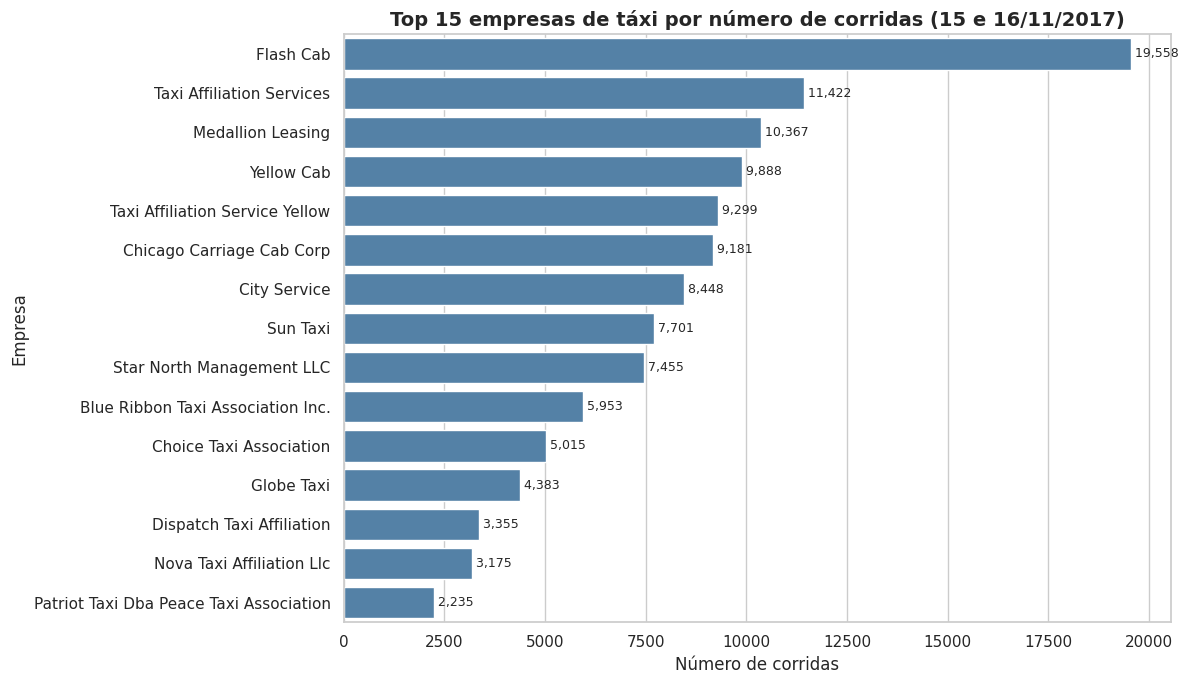

In [9]:
companies_sorted = df_companies.sort_values('trips_amount', ascending=False)
top15_companies = companies_sorted.head(15)

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(data=top15_companies, y='company_name', x='trips_amount', ax=ax, color='steelblue')
ax.set_title('Top 15 empresas de táxi por número de corridas (15 e 16/11/2017)')
ax.set_xlabel('Número de corridas')
ax.set_ylabel('Empresa')
# Rótulos de valor no fim de cada barra (compatível com versões antigas do matplotlib)
for patch in ax.patches:
    ax.text(patch.get_width(), patch.get_y() + patch.get_height() / 2,
            f' {patch.get_width():,.0f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

In [10]:
total_trips = companies_sorted['trips_amount'].sum()
leader = companies_sorted.iloc[0]
top5_share = companies_sorted.head(5)['trips_amount'].sum() / total_trips
top10_share = companies_sorted.head(10)['trips_amount'].sum() / total_trips

print(f'Número de empresas: {len(companies_sorted)}')
print(f'Líder: {leader.company_name} com {leader.trips_amount:,} corridas ({leader.trips_amount / total_trips:.1%} do total)')
print(f'Participação das 5 maiores: {top5_share:.1%}')
print(f'Participação das 10 maiores: {top10_share:.1%}')
print(f'Mediana de corridas por empresa: {companies_sorted["trips_amount"].median():,.0f}')

Número de empresas: 64
Líder: Flash Cab com 19,558 corridas (14.2% do total)
Participação das 5 maiores: 44.1%
Participação das 10 maiores: 72.3%
Mediana de corridas por empresa: 178


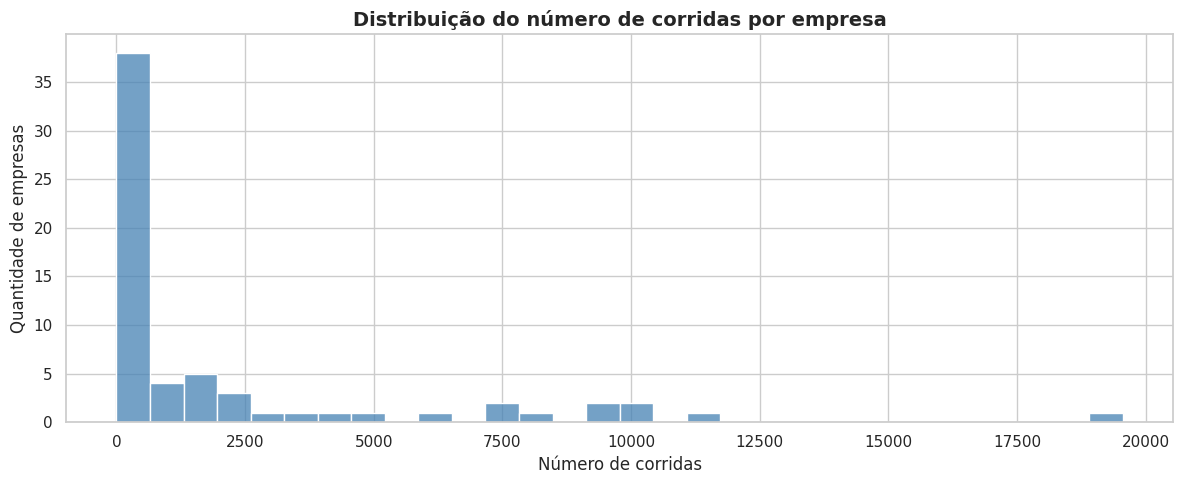

In [11]:
# Distribuição: a maioria das empresas tem poucas corridas?
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(df_companies['trips_amount'], bins=30, ax=ax, color='steelblue')
ax.set_title('Distribuição do número de corridas por empresa')
ax.set_xlabel('Número de corridas')
ax.set_ylabel('Quantidade de empresas')
plt.tight_layout()
plt.show()

**Conclusões — empresas de táxi**

- O mercado é **altamente concentrado**: a líder, **Flash Cab**, sozinha responde por **14,2%** das corridas, e as **5 maiores empresas concentram 44,1%** do total.
- A distribuição é **fortemente assimétrica à direita**: a empresa mediana fez apenas **178 corridas**, contra cerca de **19,5 mil** da líder, ou seja, mais de 100 vezes menos. A maioria das empresas é pequena e um grupo reduzido domina o volume.
- **Implicação para a Zuber:** os concorrentes diretos são poucos e grandes, então a entrada no mercado exige diferenciação clara em relação às líderes (por exemplo, preço, tempo de espera ou experiência no app).
- **Hipótese para investigar:** os passageiros das empresas pequenas podem ser mais fáceis de conquistar, caso essas empresas tenham menos escala e reconhecimento de marca. Os dados disponíveis mostram apenas o volume de corridas, então essa ideia precisa ser validada com outras informações (como preços e avaliações).

### 3.6 Gráfico: top 10 bairros por número de corridas como destino

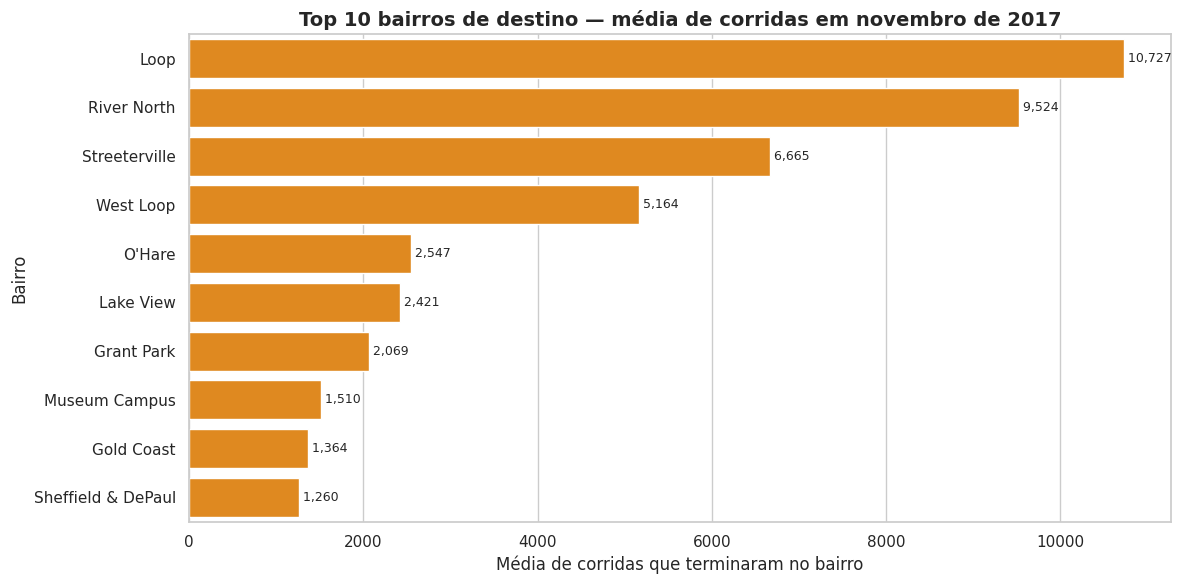

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=top10_neighborhoods, y='dropoff_location_name', x='average_trips', ax=ax, color='darkorange')
ax.set_title('Top 10 bairros de destino — média de corridas em novembro de 2017')
ax.set_xlabel('Média de corridas que terminaram no bairro')
ax.set_ylabel('Bairro')
# Rótulos de valor no fim de cada barra (compatível com versões antigas do matplotlib)
for patch in ax.patches:
    ax.text(patch.get_width(), patch.get_y() + patch.get_height() / 2,
            f' {patch.get_width():,.0f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

**Conclusões — bairros de destino**

**O que os dados mostram**
- Os destinos estão **concentrados em poucos bairros**: **Loop, River North, Streeterville e West Loop** lideram, todos na região central da cidade.
- A diferença é grande: o **Loop recebe mais de 8 vezes** a média de corridas do 10º colocado, e os **10 principais bairros somam 76,7%** de todas as corridas com destino conhecido.
- O aeroporto **O'Hare** ocupa a **5ª posição**, sendo o único destino do top 5 fora da região central.

**Implicação para a Zuber:** a demanda está no centro da cidade e no O'Hare, que são as áreas prioritárias para oferta de motoristas.

**Hipóteses para análises futuras** (não testáveis com este conjunto, que não tem distância, tarifa nem horário):
- Corridas para o aeroporto podem ser mais longas e de maior valor por corrida.
- A demanda nesses bairros pode se concentrar em horários de pico, o que orientaria a escala de motoristas.

A análise de clima a seguir investiga justamente a rota Loop → O'Hare.

## 4. Teste de hipótese: duração das corridas Loop → O'Hare em sábados chuvosos

### 4.1 Importação e estudo dos dados

In [13]:
df_trips = pd.read_csv('../data/project_sql_result_07.csv')
inspect(df_trips, 'Corridas Loop -> O\'Hare aos sábados')

===== Corridas Loop -> O'Hare aos sábados =====
Dimensões: 1068 linhas x 3 colunas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), object(2)
memory usage: 25.2+ KB

Valores ausentes por coluna:
start_ts              0
weather_conditions    0
duration_seconds      0
dtype: int64

Linhas duplicadas: 197


,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,"2,410.00"
1,2017-11-25 14:00:00,Good,"1,920.00"
2,2017-11-25 12:00:00,Good,"1,543.00"
3,2017-11-04 10:00:00,Good,"2,512.00"
4,2017-11-11 07:00:00,Good,"1,440.00"


,duration_seconds
count,"1,068.00"
mean,"2,071.73"
std,769.46
min,0.00
25%,"1,438.25"
50%,"1,980.00"
75%,"2,580.00"
max,"7,440.00"


In [14]:
# Ajuste de tipos: data/hora e categoria
df_trips['start_ts'] = pd.to_datetime(df_trips['start_ts'])
df_trips['weather_conditions'] = df_trips['weather_conditions'].astype('category')

print(df_trips.dtypes, '\n')
print('Dias da semana presentes (5 = sábado):', df_trips['start_ts'].dt.dayofweek.unique())
print('\nCorridas por condição climática:')
print(df_trips['weather_conditions'].value_counts())

start_ts              datetime64[ns]
weather_conditions          category
duration_seconds             float64
dtype: object 

Dias da semana presentes (5 = sábado): [5]

Corridas por condição climática:
Good    888
Bad     180
Name: weather_conditions, dtype: int64


**Comentário:** a coluna `start_ts` foi convertida para data/hora e confirmei que todas as corridas são de sábado. A seguir, verifico registros suspeitos antes do teste.

### 4.2 Qualidade dos dados: durações inválidas e duplicados

Corridas com duração zero não são fisicamente possíveis para esse trajeto e distorceriam as médias. Também verifico linhas duplicadas.

In [15]:
zero_duration = (df_trips['duration_seconds'] <= 0).sum()
duplicates = df_trips.duplicated().sum()
print(f'Corridas com duração <= 0: {zero_duration}')
print(f'Linhas duplicadas: {duplicates}')

Corridas com duração <= 0: 6
Linhas duplicadas: 197


Sobre os **duplicados**: como `start_ts` é arredondado para a hora, corridas diferentes que começaram na mesma hora com a mesma duração aparecem idênticas. Sem um `trip_id` não dá para provar que são repetições, então **mantenho essas linhas** e removo apenas as durações inválidas.

In [16]:
df_trips_clean = df_trips[df_trips['duration_seconds'] > 0].copy()
df_trips_clean['duration_minutes'] = df_trips_clean['duration_seconds'] / 60

print(f'Registros antes: {len(df_trips)} | depois: {len(df_trips_clean)}')
df_trips_clean.groupby('weather_conditions', observed=True)['duration_minutes'].describe()

Registros antes: 1068 | depois: 1062


,count,mean,std,min,25%,50%,75%,max
weather_conditions,,,,,,,,
Good,882.00,33.55,12.39,1.00,23.29,30.00,41.00,124.00
Bad,180.00,40.45,12.02,8.00,32.70,42.33,48.80,83.00


### 4.3 Valores extremos

O resumo acima ainda mostra durações muito curtas (mínimo de 1 minuto no grupo Good e 8 minutos no Bad) e muito longas (máximo de 124 minutos). O trajeto do Loop até O'Hare tem cerca de 27 km, então corridas de poucos minutos são improváveis e indicam erro de registro. Já as corridas longas podem ser reais (congestionamento ou acidente), mas também podem ser erros.

Para não decidir no olho, identifico os extremos pela regra do **intervalo interquartil (IQR)**, calculada separadamente em cada grupo: valores abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR são considerados atípicos.

In [17]:
def iqr_bounds(series):
    """Limites inferior e superior pela regra 1,5 x IQR."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

bounds = df_trips_clean.groupby('weather_conditions', observed=True)['duration_minutes'].apply(iqr_bounds)

is_outlier = pd.Series(False, index=df_trips_clean.index)
for condition, (low, high) in bounds.items():
    mask = df_trips_clean['weather_conditions'] == condition
    group_outliers = mask & ~df_trips_clean['duration_minutes'].between(low, high)
    is_outlier |= group_outliers
    print(f'{condition}: limites = [{low:.1f}, {high:.1f}] min | atípicos = {group_outliers.sum()}')

print(f'\nTotal de atípicos: {is_outlier.sum()} de {len(df_trips_clean)} corridas ({is_outlier.mean():.1%})')
df_trips_clean.loc[is_outlier, ['start_ts', 'weather_conditions', 'duration_minutes']].sort_values('duration_minutes')

Good: limites = [-3.3, 67.6] min | atípicos = 6
Bad: limites = [8.6, 72.9] min | atípicos = 3

Total de atípicos: 9 de 1062 corridas (0.8%)


,start_ts,weather_conditions,duration_minutes
203,2017-11-18 00:00:00,Bad,8.00
860,2017-11-04 18:00:00,Bad,8.00
353,2017-11-25 18:00:00,Good,69.00
646,2017-11-11 13:00:00,Good,73.00
79,2017-11-11 15:00:00,Good,80.00
276,2017-11-18 12:00:00,Bad,83.00
583,2017-11-11 16:00:00,Good,83.00
619,2017-11-25 14:00:00,Good,107.00
354,2017-11-25 11:00:00,Good,124.00


**Decisão:** o teste principal é feito **com todas as corridas de duração positiva**, porque os valores atípicos são poucos e não há como provar que sejam erros. Para garantir que eles não estão definindo o resultado, repito o teste **sem os atípicos** como verificação de robustez (seção 4.6). Se as duas versões levarem à mesma conclusão, ela é confiável.

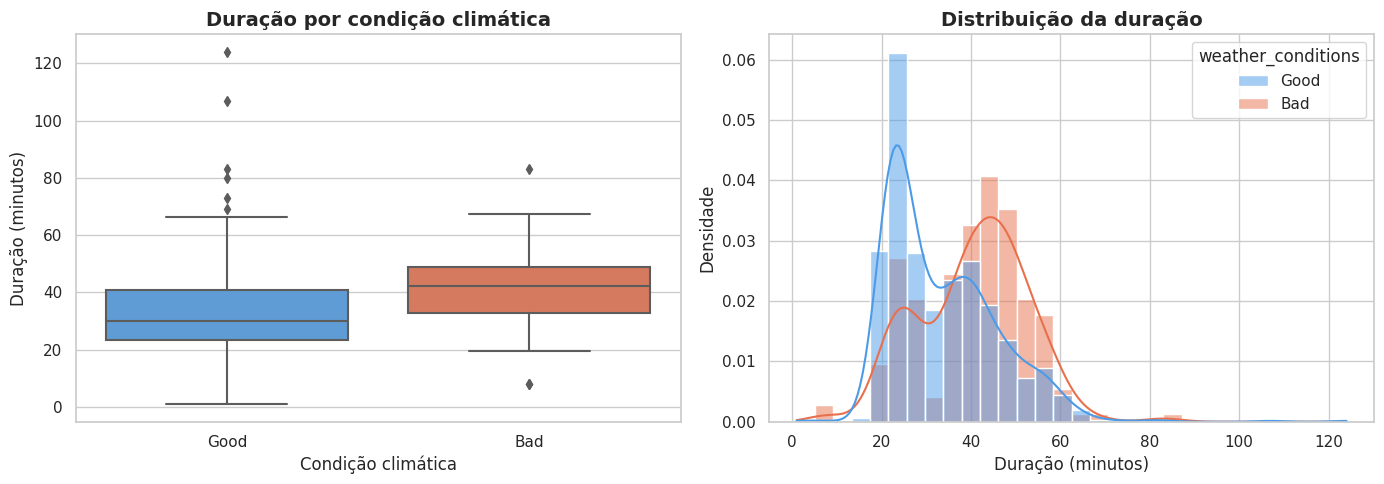

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_trips_clean, x='weather_conditions', y='duration_minutes',
            order=['Good', 'Bad'], ax=axes[0], palette=['#4C9BE8', '#E8704C'])
axes[0].set_title('Duração por condição climática')
axes[0].set_xlabel('Condição climática')
axes[0].set_ylabel('Duração (minutos)')

sns.histplot(data=df_trips_clean, x='duration_minutes', hue='weather_conditions',
             hue_order=['Good', 'Bad'], bins=30, kde=True, ax=axes[1],
             palette=['#4C9BE8', '#E8704C'], stat='density', common_norm=False)
axes[1].set_title('Distribuição da duração')
axes[1].set_xlabel('Duração (minutos)')
axes[1].set_ylabel('Densidade')

plt.tight_layout()
plt.show()

**Comentário:** visualmente, as corridas com clima ruim (`Bad`) tendem a durar mais. O teste estatístico abaixo verifica se essa diferença é significativa ou pode ser fruto do acaso.

### 4.4 Formulação das hipóteses

A hipótese nula sempre afirma **ausência de diferença**, e a alternativa é o que queremos verificar. Como o enunciado fala que a duração "muda" (sem indicar direção), o teste é **bicaudal**.

- **H₀ (nula):** a duração média das corridas do Loop até O'Hare aos sábados é **igual** com clima bom e com clima ruim.
- **H₁ (alternativa):** a duração média é **diferente** entre sábados com clima bom e com clima ruim.

**Nível de significância:** α = 0,05. É o padrão mais usado em análises de negócio e equilibra o risco de concluir uma diferença que não existe (erro tipo I) com o de não detectar uma diferença real (erro tipo II).

### 4.5 Escolha do critério

Comparo as médias de **duas amostras independentes**: corridas em sábados de clima bom e de clima ruim são corridas diferentes. O critério adequado é o **teste t para amostras independentes** (`scipy.stats.ttest_ind`), na versão de **Welch** (`equal_var=False`).

- **Por que Welch:** ela não exige que os dois grupos tenham a mesma variância e, quando as variâncias são de fato iguais, perde praticamente nada em relação ao teste t de Student. Usá-la por padrão evita escolher o teste com base em um teste preliminar. O teste de Levene é mostrado apenas como informação complementar.
- **Normalidade:** com 882 e 180 corridas nos grupos, o Teorema Central do Limite garante que a distribuição das médias amostrais é aproximadamente normal, mesmo que as durações individuais não sejam.
- **Independência (ressalva):** corridas que começam na mesma hora ou no mesmo sábado compartilham o mesmo registro de clima, e os dados cobrem poucos sábados de um único mês. Por isso, a independência entre as observações é uma **aproximação**, e o p-valor tende a ser um pouco otimista.

In [19]:
alpha = 0.05

good = df_trips_clean.loc[df_trips_clean['weather_conditions'] == 'Good', 'duration_seconds']
bad = df_trips_clean.loc[df_trips_clean['weather_conditions'] == 'Bad', 'duration_seconds']

print(f'Amostra Good: n = {len(good)} | média = {good.mean()/60:.1f} min | desvio padrão = {good.std()/60:.1f} min')
print(f'Amostra Bad:  n = {len(bad)} | média = {bad.mean()/60:.1f} min | desvio padrão = {bad.std()/60:.1f} min')

# Informação complementar: igualdade de variâncias
levene_stat, levene_p = st.levene(good, bad)
print(f'\nLevene (informativo): p-valor = {levene_p:.4f}')

Amostra Good: n = 882 | média = 33.6 min | desvio padrão = 12.4 min
Amostra Bad:  n = 180 | média = 40.5 min | desvio padrão = 12.0 min

Levene (informativo): p-valor = 0.6687


In [20]:
results = st.ttest_ind(good, bad, equal_var=False)  # teste t de Welch

print(f'Estatística t: {results.statistic:.3f}')
print(f'p-valor: {results.pvalue:.2e}')

if results.pvalue < alpha:
    print('\nRejeitamos a hipótese nula: a duração média muda em sábados chuvosos.')
else:
    print('\nNão podemos rejeitar a hipótese nula: não há evidência de que a duração média mude em sábados chuvosos.')

diff_min = (bad.mean() - good.mean()) / 60
print(f'\nDiferença média (Bad - Good): {diff_min:+.1f} minutos ({(bad.mean() / good.mean() - 1):+.1%})')

Estatística t: -6.979
p-valor: 2.42e-11

Rejeitamos a hipótese nula: a duração média muda em sábados chuvosos.

Diferença média (Bad - Good): +6.9 minutos (+20.6%)


### 4.6 Verificação de robustez: teste sem os valores atípicos

Repito o mesmo teste removendo as corridas marcadas como atípicas na seção 4.3, para confirmar que a conclusão não depende delas.

In [21]:
df_no_outliers = df_trips_clean[~is_outlier]
good_r = df_no_outliers.loc[df_no_outliers['weather_conditions'] == 'Good', 'duration_seconds']
bad_r = df_no_outliers.loc[df_no_outliers['weather_conditions'] == 'Bad', 'duration_seconds']

results_r = st.ttest_ind(good_r, bad_r, equal_var=False)
diff_r = (bad_r.mean() - good_r.mean()) / 60

summary = pd.DataFrame({
    'Corridas': [len(good) + len(bad), len(good_r) + len(bad_r)],
    'Média Good (min)': [good.mean() / 60, good_r.mean() / 60],
    'Média Bad (min)': [bad.mean() / 60, bad_r.mean() / 60],
    'Diferença (min)': [diff_min, diff_r],
    'p-valor': [f'{results.pvalue:.2e}', f'{results_r.pvalue:.2e}'],
    'Rejeita H0?': [results.pvalue < alpha, results_r.pvalue < alpha],
}, index=['Com atípicos', 'Sem atípicos'])
summary

,Corridas,Média Good (min),Média Bad (min),Diferença (min),p-valor,Rejeita H0?
Com atípicos,1062,33.55,40.45,6.90,2.42e-11,True
Sem atípicos,1053,33.17,40.58,7.41,3.87e-14,True


### 4.7 Interpretação do resultado

**Resultado:** o p-valor ficou **muito abaixo de α = 0,05**, então **rejeitamos a hipótese nula**. Há evidência estatística de que a duração média das corridas do Loop até O'Hare **muda** em sábados com chuva ou tempestade.

**Tamanho do efeito:** as corridas em sábados de clima ruim duram em média **40,5 minutos**, contra **33,5 minutos** com clima bom, ou seja, cerca de **7 minutos (aproximadamente 21%) a mais**. Esse aumento é relevante para o passageiro, especialmente em uma corrida para o aeroporto.

**Robustez:** a tabela da seção 4.6 mostra que a conclusão se mantém mesmo sem os valores atípicos, então ela não é causada por poucos registros extremos.

**Possíveis explicações (hipóteses, não testadas com estes dados):** trânsito mais lento, menor visibilidade e maior cautela dos motoristas com chuva.

**Limitações**
- Os dados cobrem **apenas alguns sábados de um único mês** (novembro de 2017), o que limita a generalização.
- O clima é registrado por hora e a classificação Good/Bad é binária, baseada só na descrição.
- Corridas do mesmo sábado compartilham as mesmas condições, então as observações não são totalmente independentes.
- Outros fatores (eventos, horário do dia, obras) também influenciam a duração e não foram controlados.

## 5. Conclusão geral

1. **Coleta de dados:** os registros de clima de Chicago em novembro de 2017 foram extraídos via web scraping e cruzados com as corridas no banco de dados pela hora de início.
2. **Concorrência:** o mercado é concentrado. A Flash Cab tem 14,2% das corridas e as 5 maiores empresas somam 44,1%, enquanto a empresa mediana fez apenas 178 corridas.
3. **Destinos:** Loop, River North, Streeterville e West Loop lideram, e os 10 principais bairros concentram 76,7% das corridas. O aeroporto O'Hare é o 5º destino mais procurado.
4. **Clima:** em sábados com chuva ou tempestade, as corridas Loop → O'Hare duram cerca de 7 minutos (21%) a mais, diferença estatisticamente significativa e robusta à remoção de valores atípicos.

**Recomendações para a Zuber**
- Concentrar a oferta de motoristas no centro da cidade e na rota para o O'Hare, onde está a maior demanda.
- Considerar a previsão do tempo nas estimativas de tempo de viagem para o aeroporto, já que o clima ruim aumenta a duração das corridas.
- Validar as hipóteses levantadas (valor das corridas para o aeroporto, horários de pico, efeito do clima em outros dias e meses) com dados mais completos, incluindo distância, tarifa e horário.